<h1><center>Практическая работа №2</center></h1>

<h1><center>"Графики"</center></h1>

<h3>Цель работы: составить графики, проанализировать их.</h3>

<h2>Задание на практическую работу: </h2>
<h3>На собственном датасете.</h3>
<h4>Продемонстрировать график количества значений категориального атрибута (countplot);</h4>
<ul>
    <li>указать наибольший из признаков</li>
    <li>указать наименьший из признаков</li>
</ul>
<h4>Отобразить среднее значение атрибутов (barplot);</h4>
<ul>
    <li>указать наибольшее среднее значение</li>
    <li>указать наибольший доверительный интервал</li>
    <li>указать наименьшее среднее значение (может быть несколько вариантов)</li>
</ul>
<h4>Реализовать ящик с усами (boxplot);</h4>
<ul>
    <li>указать наибольшую медиану</li>
    <li>указать наибольшее количество выбросов</li>
    <li>указать наименьшее количество выбросов</li>
</ul>
<h4>Сделать тепловую карту корреляции (heatmap);</h4>
<ul>
    <li>указать наибольшую корреляцию между признаками и сделать вывод по этому (можно описать несколько самых взаимосвязанных)</li>
    <li>указать наименьшую корреляцию между признаками и сделать вывод по этому</li>
    <li>описать холодные цвета или отрицательные значения</li>
</ul>
<h4>Показать соотношение между атрибутами (piarplot или pairgrid);</h4>
<ul>
    <li>Примечание: все графики описываем.</li>
</ul>
<h4>Использовать несколько иных графиков и/или качественно видоизменить пройденные (не менее 2-х), на их основе вывести информацию (интерпретировать графики).</h4>

<h3>Ход работы:</h3>

In [1]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

<h2>Датасет</h2>
<p>Используется датасет статистики матчей VCT (Valorant Champions Tour), обработанный в практической работе №1: файл <code>overview_processed.csv</code> — статистика каждого игрока на каждой карте сезона 2025.</p>
<ul>
    <li>категориальные признаки: <code>Tournament</code>, <code>Stage</code>, <code>Match Type</code>, <code>Match Name</code>, <code>Map</code>, <code>Player</code>, <code>Team</code>, <code>Agents</code>;</li>
    <li>числовые признаки: <code>Rating</code> (рейтинг), <code>Average Combat Score</code> (ACS), <code>Kills</code>, <code>Deaths</code>, <code>Assists</code>, <code>Kill, Assist, Trade, Survive %</code> (KAST), <code>Average Damage Per Round</code> (ADR), <code>Headshot %</code>, <code>First Kills</code>, <code>First Deaths</code>.</li>
</ul>

In [2]:
mypath = 'C:/Users/ivank/Documents/mpt/ml/datasets/processed/overview_processed.csv'
mydf = pd.read_csv(mypath, index_col = 0)
mydf

,Tournament,Stage,Match Type,Match Name,Map,Player,Team,Agents,Rating,Average Combat Score,Kills,Deaths,Assists,"Kill, Assist, Trade, Survive %",Average Damage Per Round,Headshot %,First Kills,First Deaths
25656,VCT 2025: EMEA Stage 1,Group Stage,Week 3,Natus Vincere vs GIANTX,Split,hiro,Natus Vincere,vyse,2.66,397.0,22.0,2.0,7.0,100.0,262.0,26.0,1.0,0.0
26301,VCT 2025: EMEA Stage 1,Group Stage,Week 4,Gentle Mates vs BBL Esports,Haven,sociablEE,BBL Esports,sova,2.61,421.0,26.0,4.0,7.0,93.0,282.0,38.0,2.0,0.0
21090,VCT 2025: China Stage 2,Playoffs,Lower Round 2,Xi Lai Gaming vs All Gamers,Lotus,Rarga,Xi Lai Gaming,sage,2.54,452.0,23.0,4.0,12.0,93.0,247.0,29.0,2.0,0.0
28416,VCT 2025: EMEA Stage 1,Playoffs,Grand Final,FNATIC vs Team Heretics,Split,kaajak,FNATIC,yoru,2.47,419.0,28.0,5.0,2.0,94.0,272.0,43.0,4.0,2.0
38976,VCT 2025: Americas Stage 1,Group Stage,Week 3,G2 Esports vs NRG,Lotus,jawgemo,G2 Esports,yoru,2.46,460.0,27.0,7.0,5.0,100.0,294.0,30.0,2.0,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
28413,VCT 2025: EMEA Stage 1,Playoffs,Lower Final,Team Heretics vs Team Liquid,Icebox,nAts,Team Liquid,viper,0.03,54.0,1.0,15.0,4.0,20.0,54.0,6.0,0.0,3.0
18147,VCT 2025: China Stage 2,Group Stage,Week 2,TYLOO vs Titan Esports Club,Haven,TvirusLuke,Titan Esports Club,jett,0.03,22.0,0.0,15.0,3.0,33.0,22.0,0.0,0.0,3.0
36333,VCT 2025: China Stage 1,Playoffs,Upper Round 1,Xi Lai Gaming vs Nova Esports,Ascent,o0o0o,Nova Esports,breach,0.03,60.0,2.0,15.0,2.0,33.0,44.0,17.0,0.0,2.0
9252,VCT 2025: EMEA Stage 2,Group Stage,Week 2,FUT Esports vs Team Vitality,Haven,MrFaliN,FUT Esports,sova,0.03,27.0,0.0,14.0,3.0,33.0,27.0,0.0,0.0,1.0


<h2>1. График количества значений категориального атрибута (countplot)</h2>
<p>Сколько раз сыграна каждая карта (одна строка — один игрок на карте).</p>

<p><b>Зачем это нужно:</b> показывает, как распределены значения категориального признака: какие категории встречаются часто, а какие редко. Так видно, сбалансированы ли данные — если категорий мало в выборке, выводы по ним будут ненадёжными.</p>

<p><b>Команды:</b></p>
<ul>
    <li><code>plt.figure(figsize = (20,10))</code> — создаёт полотно для графика размером 20×10 дюймов</li>
    <li><code>sns.countplot(data = mydf, x = 'Map', order = ...)</code> — считает количество строк для каждого значения <code>Map</code> и рисует столбики</li>
    <li><code>mydf['Map'].value_counts()</code> — считает, сколько раз встречается каждое значение; <code>.index</code> — названия в порядке убывания, по ним сортируются столбики</li>
    <li><code>plt.title(...)</code> — заголовок графика</li>
    <li><code>plt.show()</code> — выводит график</li>
</ul>

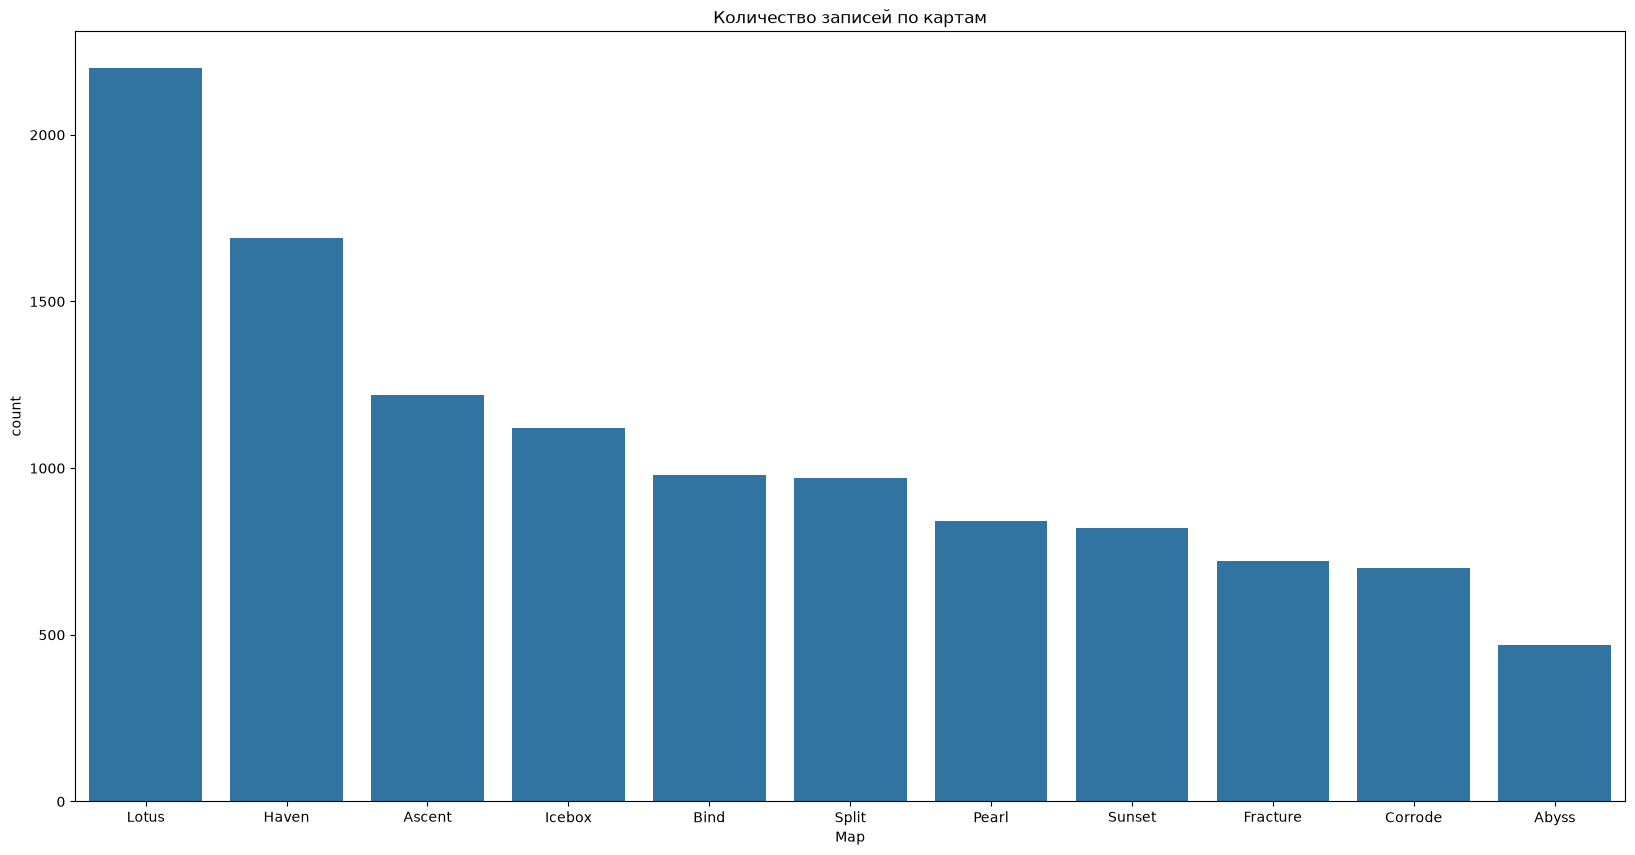

Map
Lotus       2200
Haven       1690
Ascent      1220
Icebox      1120
Bind         980
Split        970
Pearl        840
Sunset       820
Fracture     720
Corrode      700
Abyss        470
Name: count, dtype: int64


In [3]:
plt.figure(figsize = (20,10))
sns.countplot(data = mydf, x = 'Map', order = mydf['Map'].value_counts().index)
plt.title('Количество записей по картам')
plt.show()
print(mydf['Map'].value_counts())

<p><b>Ответ:</b></p>
<ul>
    <li>наибольший признак — <b>Lotus</b> (2200 записей): самая популярная карта сезона;</li>
    <li>наименьший признак — <b>Abyss</b> (470 записей): её играли реже всех, почти в 5 раз реже, чем Lotus.</li>
</ul>

<h2>2. Среднее значение атрибутов (barplot)</h2>
<p>Берём признаки с одинаковым масштабом (количество за карту): убийства, смерти, помощь, первые убийства и первые смерти. ACS и ADR измеряются сотнями и сделали бы остальные столбцы почти невидимыми. Чёрные линии — 95% доверительный интервал.</p>

<p><b>Зачем это нужно:</b> позволяет сравнить средние значения разных признаков и по доверительному интервалу оценить, насколько этим средним можно доверять: чем уже интервал, тем точнее среднее.</p>

<p><b>Команды:</b></p>
<ul>
    <li><code>cols = [...]</code> — список признаков одного масштаба (если взять ACS и ADR, они в сотни раз больше и остальные столбики станут не видны)</li>
    <li><code>plt.figure(figsize = (20,10))</code> — создаёт полотно для графика размером 20×10 дюймов</li>
    <li><code>sns.barplot(data = mydf[cols])</code> — рисует среднее каждого признака; чёрная черта на столбике — 95% доверительный интервал</li>
    <li><code>mydf[cols].mean()</code> — среднее значение каждого признака</li>
    <li><code>mydf[cols].std()</code> — стандартное отклонение (разброс значений)</li>
    <li><code>1.96 * std / np.sqrt(len(mydf))</code> — формула 95% доверительного интервала: на сколько среднее может отличаться от настоящего</li>
    <li><code>pd.DataFrame({...})</code> — собирает средние и интервалы в одну таблицу</li>
    <li><code>plt.title(...)</code> — заголовок графика</li>
    <li><code>plt.show()</code> — выводит график</li>
</ul>

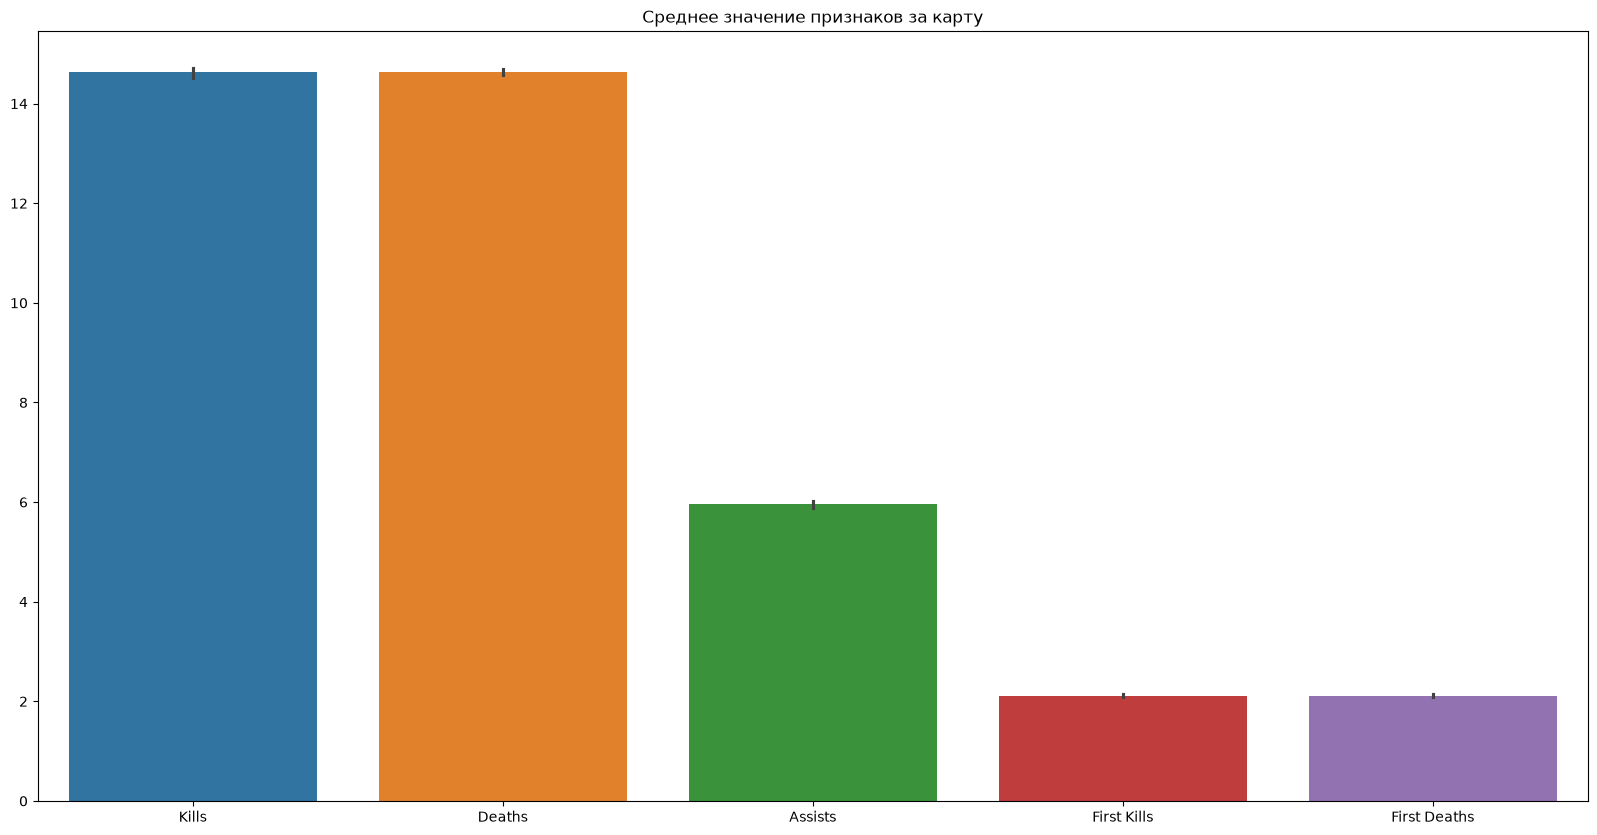

              Среднее  Доверительный интервал (±)
Kills           14.63                       0.097
Deaths          14.64                       0.066
Assists          5.95                       0.066
First Kills      2.12                       0.032
First Deaths     2.12                       0.030


In [4]:
cols = ['Kills', 'Deaths', 'Assists', 'First Kills', 'First Deaths']
plt.figure(figsize = (20,10))
sns.barplot(data = mydf[cols])
plt.title('Среднее значение признаков за карту')
plt.show()
ci = 1.96 * mydf[cols].std() / np.sqrt(len(mydf))
print(pd.DataFrame({'Среднее': mydf[cols].mean().round(2), 'Доверительный интервал (±)': ci.round(3)}))

<p><b>Ответ:</b></p>
<ul>
    <li>наибольшее среднее значение — <b>Deaths</b> (14.64) и практически такое же у <b>Kills</b> (14.63): в среднем игрок за карту убивает столько же, сколько умирает;</li>
    <li>наибольший доверительный интервал — у <b>Kills</b> (±0.097): количество убийств сильнее всего различается от игрока к игроку;</li>
    <li>наименьшее среднее значение — <b>First Kills</b> и <b>First Deaths</b> (по 2.12): первое убийство в раунде одно, поэтому у всех игроков их мало, и в сумме первых убийств и первых смертей поровну.</li>
</ul>

<h2>3. Ящик с усами (boxplot)</h2>
<p>Те же признаки: медиана (линия внутри ящика), межквартильный размах (ящик) и выбросы (точки за усами).</p>

<p><b>Зачем это нужно:</b> показывает разброс значений, медиану и выбросы. Выбросы — нетипичные значения, которые могут исказить среднее и обучение модели, поэтому их важно заметить заранее.</p>

<p><b>Команды:</b></p>
<ul>
    <li><code>plt.figure(figsize = (20,10))</code> — создаёт полотно для графика размером 20×10 дюймов</li>
    <li><code>sns.boxplot(data = mydf[cols])</code> — рисует ящик для каждого признака: линия внутри — медиана, ящик — средние 50% значений, точки за усами — выбросы</li>
    <li><code>quantile(0.25) / quantile(0.75)</code> — первый и третий квартили — нижняя и верхняя границы ящика</li>
    <li><code>iqr = q3 - q1</code> — межквартильный размах — высота ящика</li>
    <li><code>q1 - 1.5 * iqr, q3 + 1.5 * iqr</code> — границы усов; всё, что за ними, — выброс</li>
    <li><code>(... | ...).sum()</code> — <code>|</code> — «или», <code>.sum()</code> — сколько значений попало за усы</li>
    <li><code>median()</code> — медиана — середина значений</li>
    <li><code>plt.title(...)</code> — заголовок графика</li>
    <li><code>plt.show()</code> — выводит график</li>
</ul>

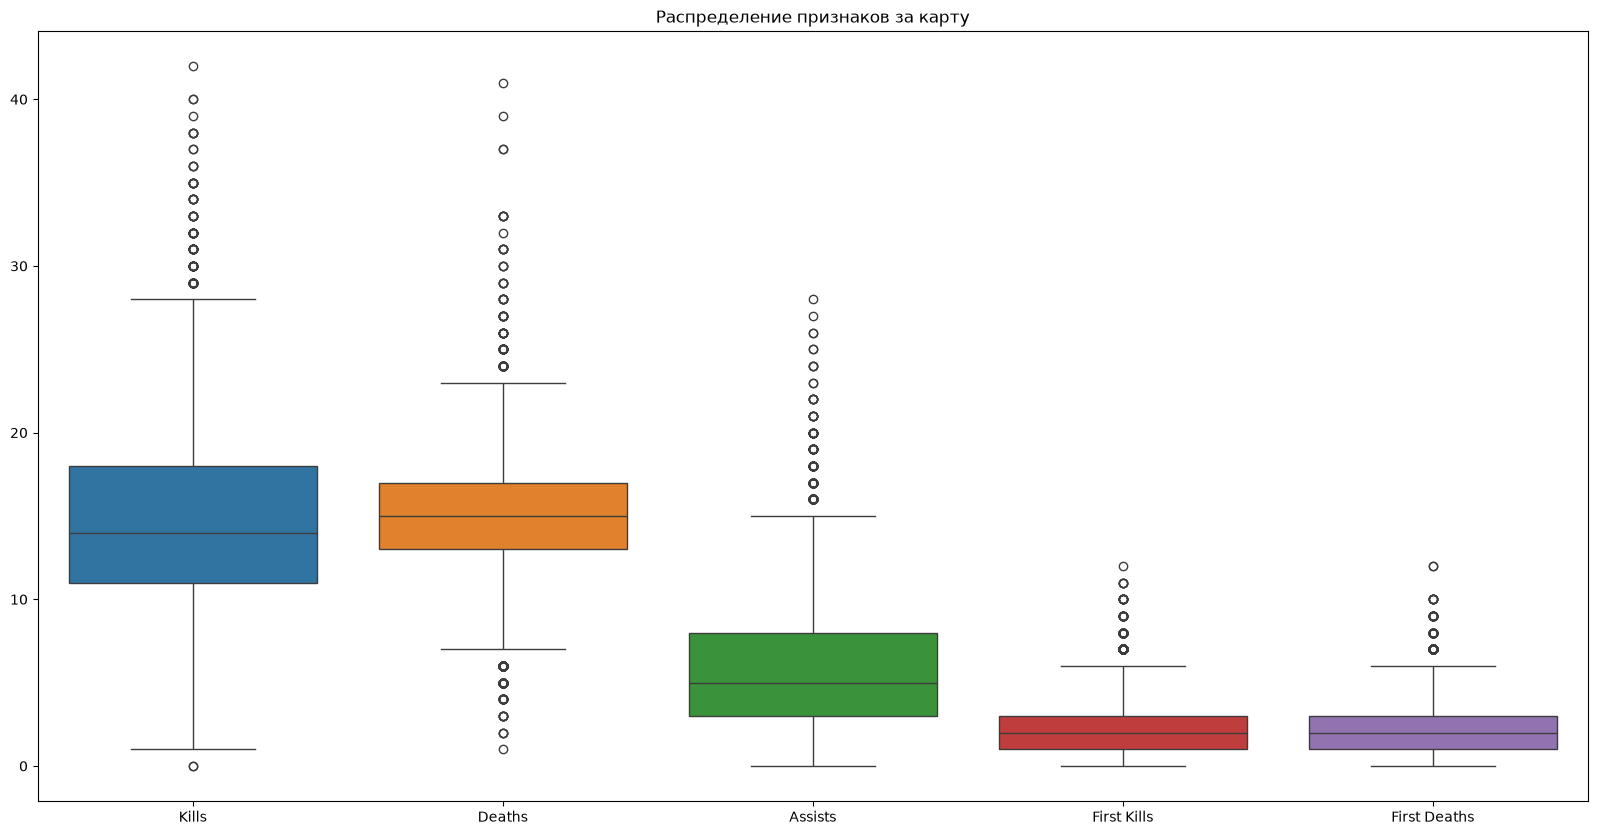

              Медиана  Выбросов
Kills            14.0       129
Deaths           15.0       354
Assists           5.0       222
First Kills       2.0       277
First Deaths      2.0       205


In [5]:
plt.figure(figsize = (20,10))
sns.boxplot(data = mydf[cols])
plt.title('Распределение признаков за карту')
plt.show()
q1 = mydf[cols].quantile(0.25)
q3 = mydf[cols].quantile(0.75)
iqr = q3 - q1
outliers = ((mydf[cols] < q1 - 1.5 * iqr) | (mydf[cols] > q3 + 1.5 * iqr)).sum()
print(pd.DataFrame({'Медиана': mydf[cols].median(), 'Выбросов': outliers}))

<p><b>Ответ:</b></p>
<ul>
    <li>наибольшая медиана — у <b>Deaths</b> (15);</li>
    <li>наибольшее количество выбросов — у <b>Deaths</b> (354): ящик у смертей узкий (от 13 до 17), поэтому и очень короткие карты с малым числом смертей, и затяжные карты с овертаймами выходят за усы;</li>
    <li>наименьшее количество выбросов — у <b>Kills</b> (129): убийства распределены шире, поэтому за усы выходит меньше значений.</li>
</ul>

<h2>4. Тепловая карта корреляции (heatmap)</h2>

<p><b>Зачем это нужно:</b> показывает, какие признаки связаны между собой. Сильно связанные признаки дублируют друг друга (один можно убрать), а признаки, связанные с целевым, помогают его прогнозировать.</p>

<p><b>Команды:</b></p>
<ul>
    <li><code>plt.figure(figsize = (20,10))</code> — создаёт полотно для графика размером 20×10 дюймов</li>
    <li><code>mydf.select_dtypes('number')</code> — оставляет только числовые столбцы</li>
    <li><code>.corr()</code> — считает корреляцию: от −1 (один растёт — другой падает) через 0 (не связаны) до 1 (растут вместе)</li>
    <li><code>sns.heatmap(..., cmap = 'coolwarm', annot = True)</code> — рисует таблицу корреляций цветом: синий — отрицательная, красный — положительная; <code>annot</code> пишет числа в клетках</li>
    <li><code>plt.title(...)</code> — заголовок графика</li>
    <li><code>plt.show()</code> — выводит график</li>
</ul>

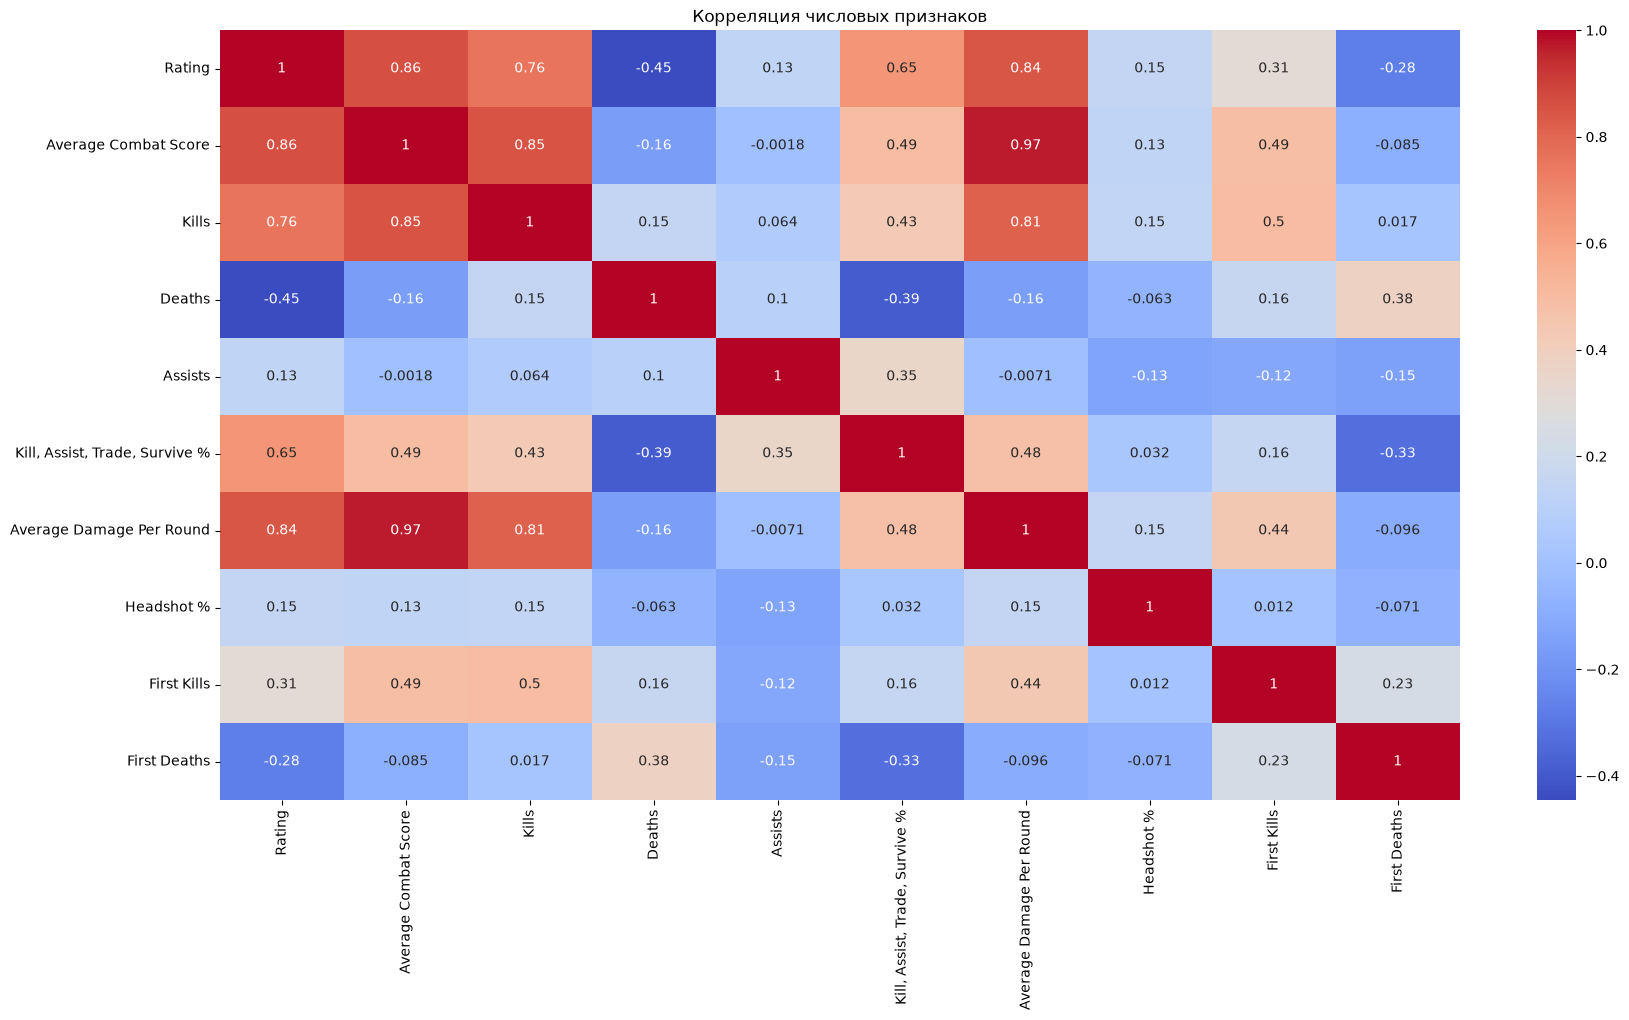

In [6]:
plt.figure(figsize = (20,10))
sns.heatmap(mydf.select_dtypes('number').corr(), cmap = 'coolwarm', annot = True)
plt.title('Корреляция числовых признаков')
plt.show()

<p><b>Ответ:</b></p>
<ul>
    <li>наибольшая корреляция — <b>Average Combat Score и Average Damage Per Round (0.97)</b>: ACS почти полностью считается из нанесённого урона. Также сильно связаны <b>Rating и ACS (0.86)</b>, <b>ACS и Kills (0.85)</b>, <b>Rating и ADR (0.84)</b>: рейтинг игрока в основном определяется уроном и убийствами;</li>
    <li>наименьшая корреляция (около 0) — <b>ACS и Assists (0.00)</b>, <b>Assists и ADR (−0.01)</b>: помощь команде никак не отражается в боевом счёте и уроне, это разные стороны игры;</li>
    <li>холодные цвета (отрицательные значения) — в основном у <b>Deaths</b> и <b>First Deaths</b>: <b>Rating и Deaths (−0.45)</b>, <b>Deaths и KAST (−0.39)</b>, <b>KAST и First Deaths (−0.33)</b>. Чем чаще игрок умирает, тем ниже его рейтинг и тем реже он полезен в раунде.</li>
</ul>

<h2>5. Соотношение между атрибутами (pairplot)</h2>
<p>Берём четыре основных признака: рейтинг, боевой счёт, убийства и смерти.</p>

<p><b>Зачем это нужно:</b> показывает сразу все попарные зависимости и форму распределения каждого признака. На точечных графиках видно то, что не видно в одном числе корреляции: направление связи, разброс и группы точек.</p>

<p><b>Команды:</b></p>
<ul>
    <li><code>sns.pairplot(mydf[[...]])</code> — сетка графиков: на диагонали — гистограмма каждого признака, в остальных клетках — точечный график «признак против признака»</li>
    <li><code>plot_kws = {'alpha': 0.3, 's': 10}</code> — полупрозрачные мелкие точки, иначе 11 тысяч точек слипнутся в пятно</li>
    <li><code>plt.show()</code> — выводит график</li>
</ul>

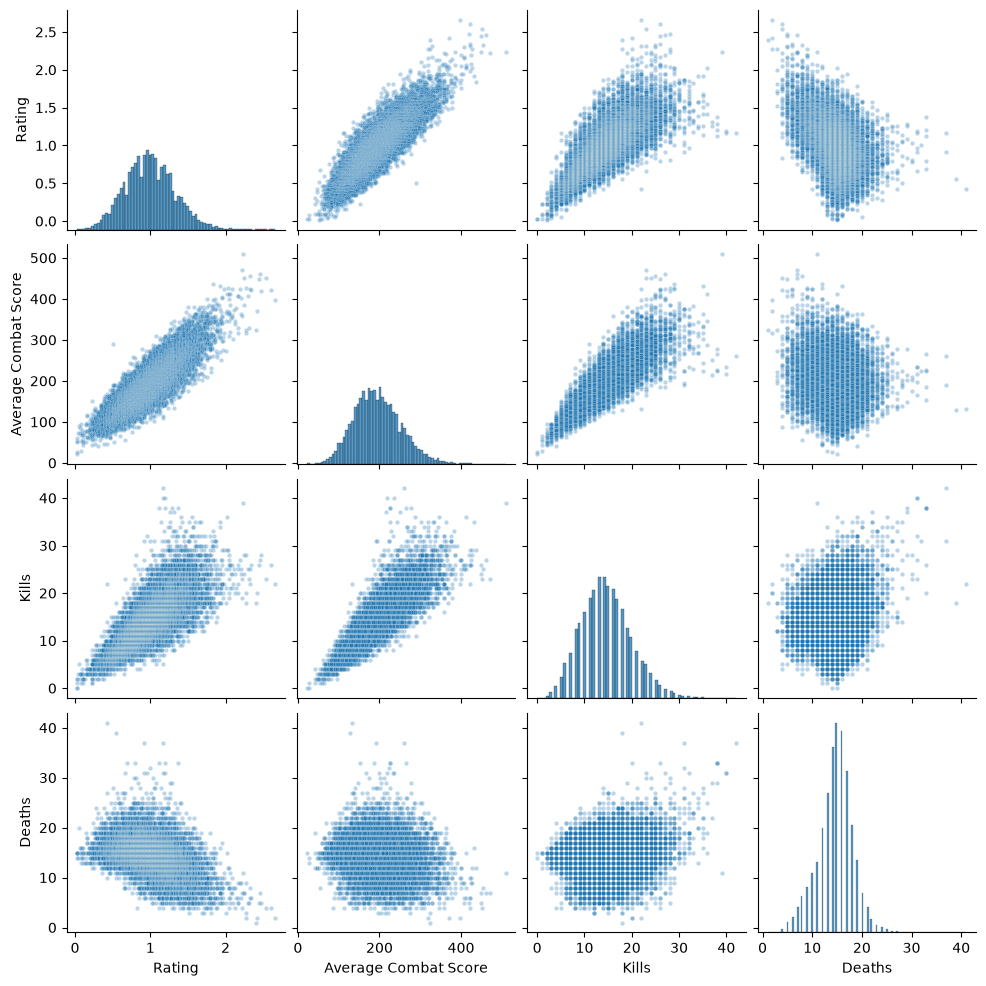

In [7]:
sns.pairplot(mydf[['Rating', 'Average Combat Score', 'Kills', 'Deaths']], plot_kws = {'alpha': 0.3, 's': 10})
plt.show()

<p><b>Ответ:</b></p>
<ul>
    <li>на диагонали — распределения признаков: все четыре похожи на нормальное с небольшим хвостом вправо (редкие очень удачные или очень длинные карты);</li>
    <li><b>Rating, ACS и Kills</b> образуют вытянутые облака вдоль диагонали: при росте одного растут и остальные (сильная положительная связь);</li>
    <li><b>Deaths</b> с рейтингом образует облако с наклоном вниз: чем больше смертей, тем ниже рейтинг;</li>
    <li><b>Kills и Deaths</b> связаны слабо (корреляция 0.15, облако почти круглое): при одинаковом числе смертей игрок может набрать как мало, так и много убийств.</li>
</ul>

<h2>6. Другие графики</h2>
<h3>6.1 Гистограмма рейтинга (histplot)</h3>

<p><b>Зачем это нужно:</b> показывает форму распределения одного признака: где сосредоточено большинство значений, есть ли перекос и длинные хвосты.</p>

<p><b>Команды:</b></p>
<ul>
    <li><code>plt.figure(figsize = (20,10))</code> — создаёт полотно для графика размером 20×10 дюймов</li>
    <li><code>sns.histplot(data = mydf, x = 'Rating', kde = True)</code> — гистограмма рейтинга; <code>kde</code> добавляет сглаженную кривую</li>
    <li><code>plt.axvline(mean, color = 'red', linestyle = '--')</code> — вертикальная пунктирная линия на месте среднего</li>
    <li><code>plt.legend()</code> — подпись к линии</li>
    <li><code>mydf['Rating'].describe()</code> — среднее, квартили, минимум и максимум</li>
    <li><code>(mydf['Rating'] > 1).mean()</code> — доля строк, где рейтинг выше 1.0</li>
    <li><code>plt.title(...)</code> — заголовок графика</li>
    <li><code>plt.show()</code> — выводит график</li>
</ul>

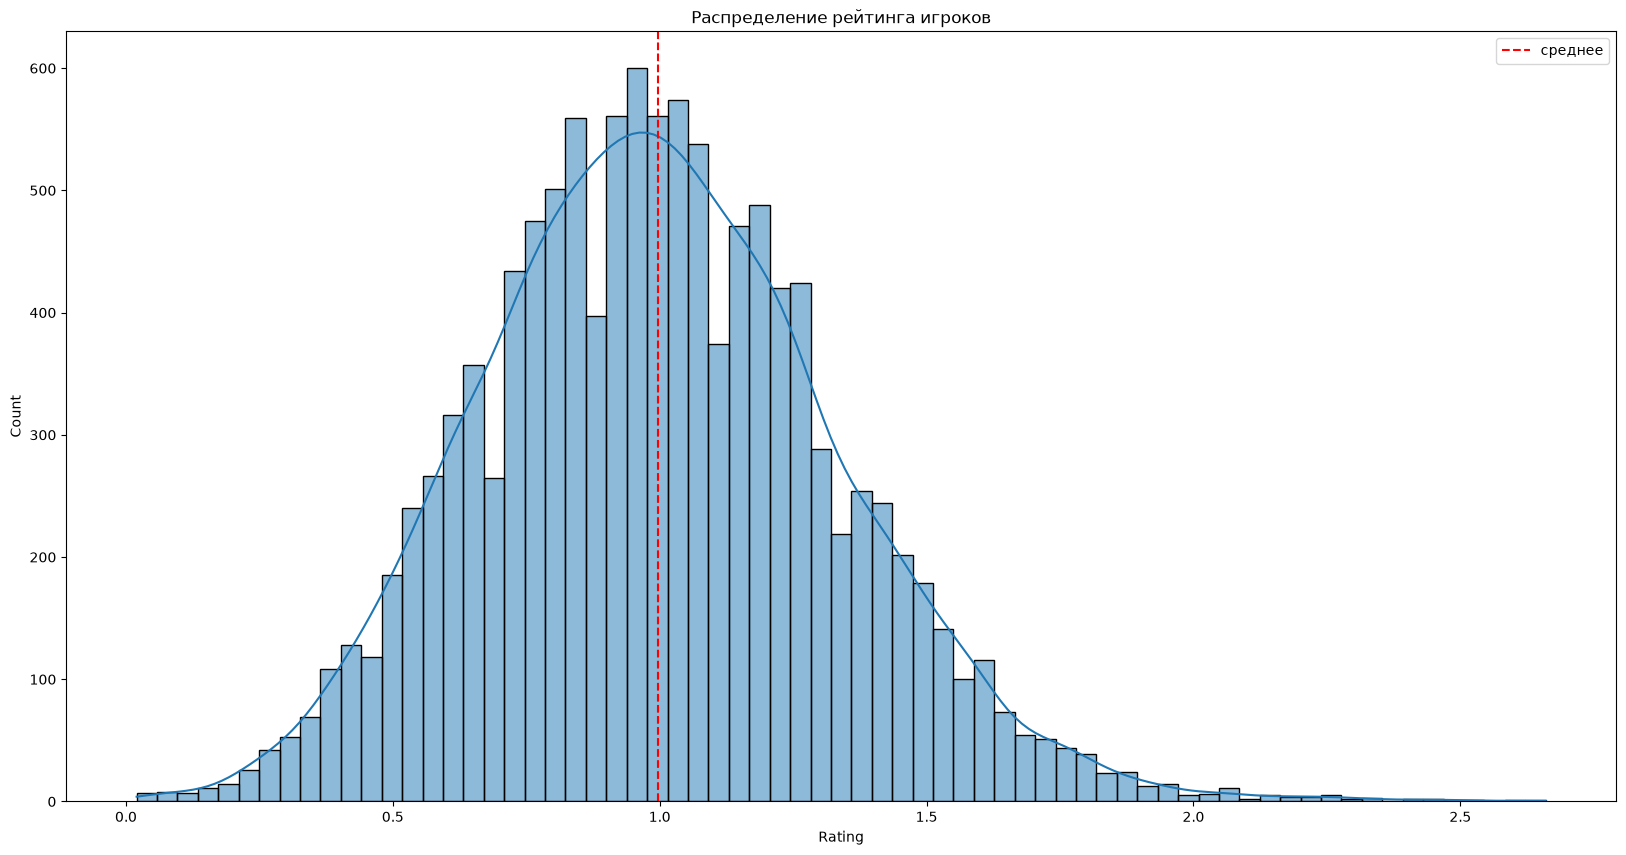

count    11730.000000
mean         0.996603
std          0.332539
min          0.020000
25%          0.770000
50%          0.980000
75%          1.210000
max          2.660000
Name: Rating, dtype: float64
Доля карт с рейтингом выше 1.0: 47.4 %


In [8]:
plt.figure(figsize = (20,10))
sns.histplot(data = mydf, x = 'Rating', kde = True)
plt.axvline(mydf['Rating'].mean(), color = 'red', linestyle = '--', label = 'среднее')
plt.legend()
plt.title('Распределение рейтинга игроков')
plt.show()
print(mydf['Rating'].describe())
print('Доля карт с рейтингом выше 1.0:', round((mydf['Rating'] > 1).mean() * 100, 1), '%')

<p><b>Ответ:</b> рейтинг распределён почти нормально вокруг <b>1.0</b> (среднее 1.00, медиана 0.98). Половина значений лежит между 0.77 и 1.21. Хвост вправо длиннее (максимум 2.66): очень удачные карты встречаются чаще, чем очень провальные. Рейтинг выше 1.0 у 47.4% карт.</p>

<h3>6.2 Ящик с усами рейтинга по картам (видоизменённый boxplot)</h3>
<p>Вместо распределения признаков сравниваем один признак (рейтинг) между категориями (картами).</p>

<p><b>Зачем это нужно:</b> сравнивает один признак между группами: отличается ли рейтинг игроков на разных картах.</p>

<p><b>Команды:</b></p>
<ul>
    <li><code>plt.figure(figsize = (20,10))</code> — создаёт полотно для графика размером 20×10 дюймов</li>
    <li><code>sns.boxplot(data = mydf, x = 'Map', y = 'Rating')</code> — отдельный ящик рейтинга для каждой карты</li>
    <li><code>groupby('Map')['Rating'].median()</code> — медиана рейтинга отдельно по каждой карте</li>
    <li><code>.sort_values().index</code> — порядок карт по возрастанию медианы</li>
    <li><code>plt.title(...)</code> — заголовок графика</li>
    <li><code>plt.show()</code> — выводит график</li>
</ul>

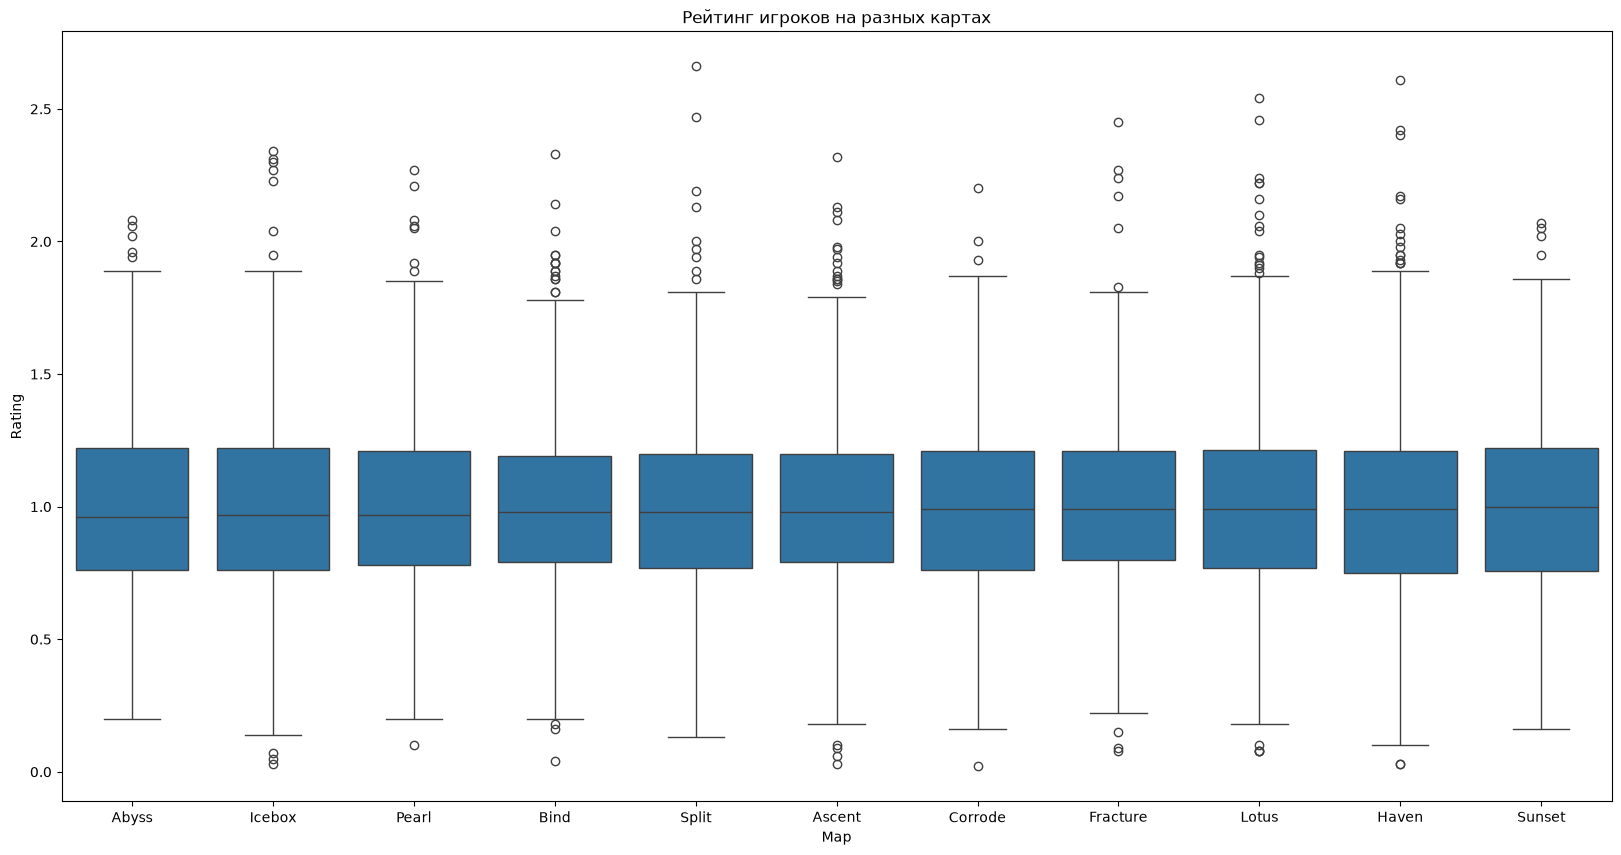

Map
Abyss       0.96
Icebox      0.97
Pearl       0.97
Bind        0.98
Split       0.98
Ascent      0.98
Corrode     0.99
Fracture    0.99
Lotus       0.99
Haven       0.99
Sunset      1.00
Name: Rating, dtype: float64


In [9]:
plt.figure(figsize = (20,10))
sns.boxplot(data = mydf, x = 'Map', y = 'Rating', order = mydf.groupby('Map')['Rating'].median().sort_values().index)
plt.title('Рейтинг игроков на разных картах')
plt.show()
print(mydf.groupby('Map')['Rating'].median().sort_values())

<p><b>Ответ:</b> медианы рейтинга на всех картах почти одинаковые: от <b>0.96 на Abyss</b> до <b>1.00 на Sunset</b>. Значит, карта почти не влияет на индивидуальную результативность игроков. Больше всего выбросов на Lotus (19), меньше всего на Corrode и Sunset (по 4), но это связано с тем, что Lotus играли чаще всего.</p>

<h3>6.3 Средний рейтинг по агентам (видоизменённый barplot)</h3>
<p>Вместо средних по признакам считаем среднее одного признака по категориям и сортируем.</p>

<p><b>Зачем это нужно:</b> показывает, на каких агентах игроки результативнее, и с помощью доверительных интервалов — для каких агентов это надёжно, а для каких данных слишком мало.</p>

<p><b>Команды:</b></p>
<ul>
    <li><code>groupby('Agents')['Rating'].mean()</code> — средний рейтинг по каждому агенту</li>
    <li><code>.sort_values(ascending = False).index</code> — агенты по убыванию среднего — порядок столбиков</li>
    <li><code>plt.figure(figsize = (20,10))</code> — создаёт полотно для графика размером 20×10 дюймов</li>
    <li><code>sns.barplot(data = mydf, x = 'Agents', y = 'Rating', order = order)</code> — средний рейтинг на каждом агенте с доверительным интервалом</li>
    <li><code>plt.xticks(rotation = 45)</code> — поворачивает подписи, чтобы не налезали друг на друга</li>
    <li><code>agg(['mean', 'count'])</code> — сразу среднее и количество карт по каждому агенту</li>
    <li><code>plt.title(...)</code> — заголовок графика</li>
    <li><code>plt.show()</code> — выводит график</li>
</ul>

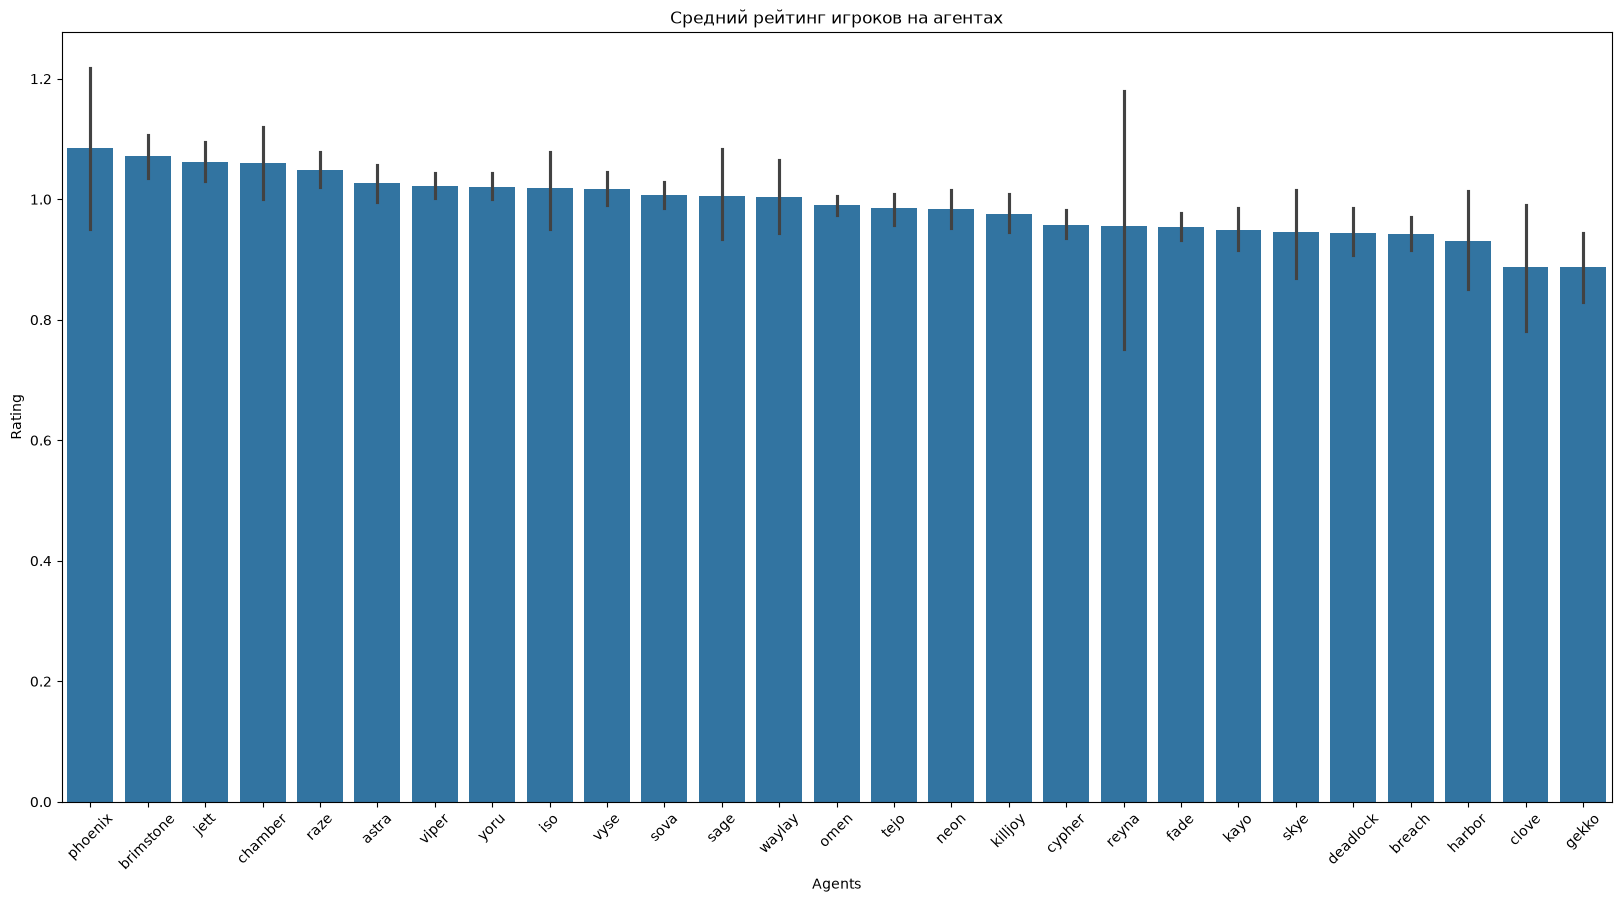

           mean  count
Agents                
phoenix    1.09     24
brimstone  1.07    281
jett       1.06    483
chamber    1.06    116
raze       1.05    633
astra      1.03    390
viper      1.02    996
yoru       1.02    860
iso        1.02    112
vyse       1.02    572
sova       1.01    944
sage       1.00     93
waylay     1.00    132
omen       0.99   1542
tejo       0.98    663
neon       0.98    536
killjoy    0.98    440
cypher     0.96    731
reyna      0.96     11
fade       0.95    731
kayo       0.95    346
skye       0.94     88
deadlock   0.94    206
breach     0.94    577
harbor     0.93     60
clove      0.89     33
gekko      0.89    130


In [10]:
order = mydf.groupby('Agents')['Rating'].mean().sort_values(ascending = False).index
plt.figure(figsize = (20,10))
sns.barplot(data = mydf, x = 'Agents', y = 'Rating', order = order)
plt.xticks(rotation = 45)
plt.title('Средний рейтинг игроков на агентах')
plt.show()
print(mydf.groupby('Agents')['Rating'].agg(['mean', 'count']).sort_values(by = 'mean', ascending = False).round(2))

<p><b>Ответ:</b> наибольший средний рейтинг у <b>Phoenix</b> (1.09), но на нём сыграно всего 24 карты, поэтому доверительный интервал очень широкий и результат ненадёжный. Выше всех среди часто играемых агентов <b>Brimstone</b> (1.07), <b>Jett</b> (1.06) и <b>Raze</b> (1.05). Ниже всего у <b>Gekko</b> и <b>Clove</b> (0.89), а также у инициаторов (Breach, Fade, KAY/O — около 0.94–0.95): их задача — помогать команде, а не набирать убийства, поэтому рейтинг у них ниже.</p>

<p>Вывод: составили графики и проанализировали их.</p>